# Mini-project: Advanced Statistical Analysis of Apple Inc. Stock Data

Objectives: using Scipy, Numpy


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

**1. Initial Data Exploration**
Load the dataset using Pandas. Check for null values and understand data types.
Examine the time series properties of the data (e.g., frequency, trends).

In [217]:
df = pd.read_csv('/content/Apple Stock Prices_1981_2023.csv')

In [5]:
df.head(3)

,Date,Open,High,Low,Close,Adj Close,Volume
0,02/01/1981,0.154018,0.155134,0.154018,0.154018,0.119849,21660800
1,05/01/1981,0.151228,0.151228,0.150670,0.150670,0.117244,35728000
2,06/01/1981,0.144531,0.144531,0.143973,0.143973,0.112032,45158400


In [4]:
# checking not null values
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10608 entries, 0 to 10607
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       10608 non-null  object 
 1   Open       10608 non-null  float64
 2   High       10608 non-null  float64
 3   Low        10608 non-null  float64
 4   Close      10608 non-null  float64
 5   Adj Close  10608 non-null  float64
 6   Volume     10608 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 580.3+ KB


,0
Date,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0


In [218]:
# check type of Date column:
df['Date'].dtype

# Convert it to date_time for proper Time Series Analysis, with date being first in the date-string:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df.head(3)

,Date,Open,High,Low,Close,Adj Close,Volume
0,1981-01-02,0.154018,0.155134,0.154018,0.154018,0.119849,21660800
1,1981-01-05,0.151228,0.151228,0.150670,0.150670,0.117244,35728000
2,1981-01-06,0.144531,0.144531,0.143973,0.143973,0.112032,45158400


Otherwise, all data is available, nothing missing, and now we have all columns in numeric formats, ordered by dates in daily frequency excl weekends/holidays (i.e. only trading dates)

**2. Data Visualization**
Utilize Matplotlib to plot closing prices and traded volume over time.
Create a candlestick chart to depict high and low prices.

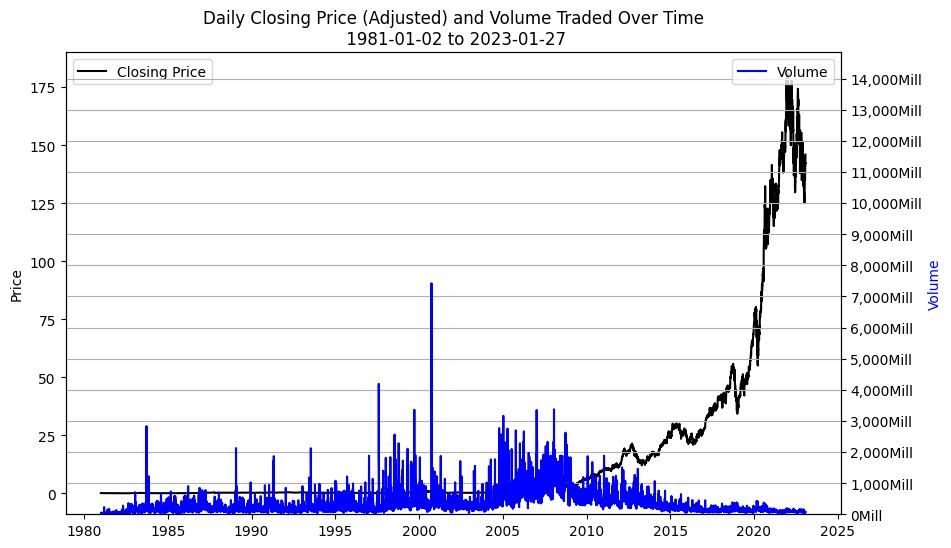

In [62]:
# Adjusted Close Price and Volume over time:
fig, ax1 = plt.subplots()
fig.set_size_inches(10, 6)


ax1.plot(df['Date'], df['Adj Close'], label='Closing Price', color='black')

ax2 = ax1.twinx()
ax2.plot(df['Date'], df['Volume'], label='Volume', color='blue')

plt.xlabel('Date') # ax1.set_xlabel('X data')
ax1.set_ylabel('Price', color='black')
ax2.set_ylabel('Volume', color='blue')
ax2.set_ylim(0, 2*df['Volume'].max())
ax2.set_yticks(ticks=np.arange(0, 2*df['Volume'].max(), 1e9),labels=[f'{x/1e6:,.0f}Mill' for x in np.arange(0, 2*df['Volume'].max(), 1e9)])

plt.title(f"Daily Closing Price (Adjusted) and Volume Traded Over Time\n {str(df['Date'].iloc[0].date())} to {str(df['Date'].iloc[-1].date())}")
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

plt.grid(True)

plt.show()

In [90]:
# Candle stick chart for High-Low
import plotly.graph_objects as go

df_candle=df[df['Date'] >= datetime.datetime(2020,1,1)].copy()

fig = go.Figure(data=[go.Candlestick(x=df_candle['Date'],
                open=df_candle['Open'],
                high=df_candle['High'],
                low=df_candle['Low'],
                close=df_candle['Close'])])

fig.show()

**3. Statistical Analysis**
Compute summary statistics (mean, median, standard deviation) for key columns.
Analyze closing prices with a moving average.

In [91]:
# key statistics for all columns
df.describe()

,Date,Open,High,Low,Close,Adj Close,Volume
count,10608,10608.000000,10608.000000,10608.000000,10608.000000,10608.000000,1.060800e+04
mean,2002-01-05 14:08:33.122171904,16.689173,16.879955,16.500822,16.697362,16.027345,3.275098e+08
min,1981-01-02 00:00:00,0.049665,0.049665,0.049107,0.049107,0.038213,0.000000e+00
25%,1991-06-27 18:00:00,0.287946,0.296875,0.282355,0.288923,0.238909,1.213044e+08
50%,2002-01-02 12:00:00,0.488839,0.495536,0.480446,0.487701,0.404851,2.145976e+08
75%,2012-07-13 18:00:00,16.320893,16.418483,16.151249,16.269554,14.073167,4.066804e+08
max,2023-01-27 00:00:00,182.630005,182.940002,179.119995,182.009995,180.959747,7.421641e+09
std,NaN,35.450519,35.882848,35.031289,35.473912,35.154878,3.378203e+08


In [107]:
# key statistics via numpy:
for col in df.columns:
  if col != 'Date':
    print(f"\nkey statistics for colum {col}:")
    print(f"- mean: {np.mean(df[col]):.4f}")
    print(f"- median: {np.median(df[col]):.4f}")
    print(f"- std: {np.std(df[col]):.4f}")


key statistics for colum Open:
- mean: 16.6892
- median: 0.4888
- std: 35.4488

key statistics for colum High:
- mean: 16.8800
- median: 0.4955
- std: 35.8812

key statistics for colum Low:
- mean: 16.5008
- median: 0.4804
- std: 35.0296

key statistics for colum Close:
- mean: 16.6974
- median: 0.4877
- std: 35.4722

key statistics for colum Adj Close:
- mean: 16.0273
- median: 0.4049
- std: 35.1532

key statistics for colum Volume:
- mean: 327509817.2606
- median: 214597600.0000
- std: 337804355.7809


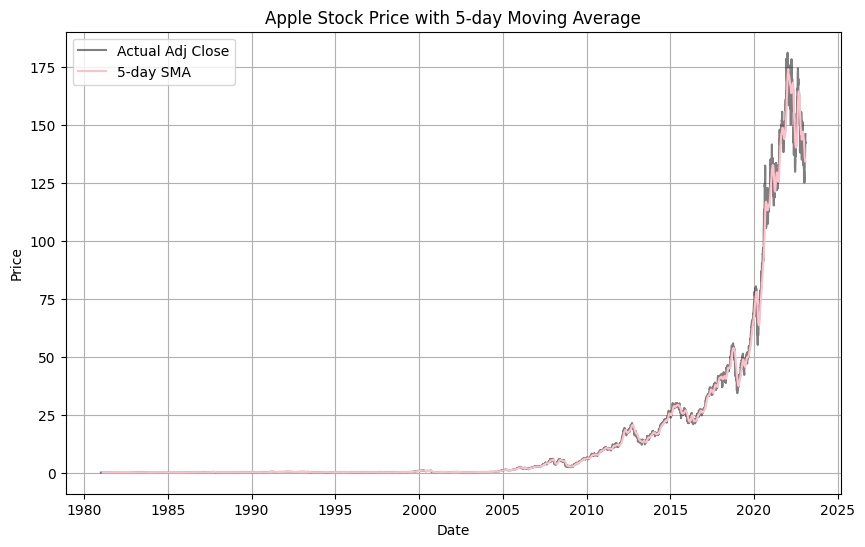

In [118]:
# moving average for the Closing Prices:
adj_close_sma = df['Adj Close'].rolling(window=30).mean()

# Plot both the original Adjusted Close and the 5-day SMA
plt.figure(figsize=(10, 6))
plt.plot(df['Date'], df['Adj Close'], label='Actual Adj Close', color='black', alpha=0.5)
plt.plot(df['Date'], adj_close_sma, label='5-day SMA', color='pink')
plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Apple Stock Price with 5-day Moving Average')
plt.legend()
plt.grid(True)
plt.show()

**4. Hypothesis Testing**
Execute a t-test to compare average closing prices across different years.
Examine daily returns’ distribution and test for normality using SciPy.

In [219]:
#adding a year column:
df['year'] = df['Date'].dt.year

# t-test on adjusted closign prices (because we should avoid effect of splits and other corp actions):
df_2022 = df[df['year'] == 2022]
df_2023 = df[df['year'] == 2023]
t_stat, p_value = stats.ttest_ind(df[df['year'] == 2022]['Adj Close'], df[df['year'] == 2023]['Adj Close'])

print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")
if p_value < 0.05:
    print("Reject the null hypothesis. There is a significant difference in closing prices between 2022 and 2023.")

t-statistic: 6.3680
p-value: 0.0000
Reject the null hypothesis. There is a significant difference in closing prices between 2022 and 2023.


In [200]:
# adding ANOVA to compare across all years:
# first, create a price table by year:

years_list = df['year'].unique()

# df_prices_by_year = pd.DataFrame()

# for year in years_list:
#   # print(f"year: {year}")
#   new_year_prices = pd.Series(df[df['year'] == year]['Adj Close'].values, name = year)

#   if year == years_list[0]:
#     df_prices_by_year[year] = new_year_prices
#   else:
#     df_prices_by_year = pd.concat([df_prices_by_year,new_year_prices], axis=1, ignore_index=False)


# f_stat, p_value = stats.f_oneway(*[df_prices_by_year[col] for col in df_prices_by_year.columns])
f_stat, p_value = stats.f_oneway(*[df[df['year'] == year]['Adj Close'].values for year in years_list])
print(f"fstatistic: {f_stat}, p_value: {p_value}")
alpha=0.01
if p_value < alpha:
    print(f"Since p={p_value} < {alpha}, reject the null hypothesis. There is a significant difference in closing prices between the years.")
else:
    print(f"Since p={p_value} >= {alpha}, can not reject the null hypothesis. There is no significant difference in closing prices between the years.")


fstatistic: 12908.92746919113, p_value: 0.0
Since p=0.0 < 0.01, reject the null hypothesis. There is a significant difference in closing prices between the years.


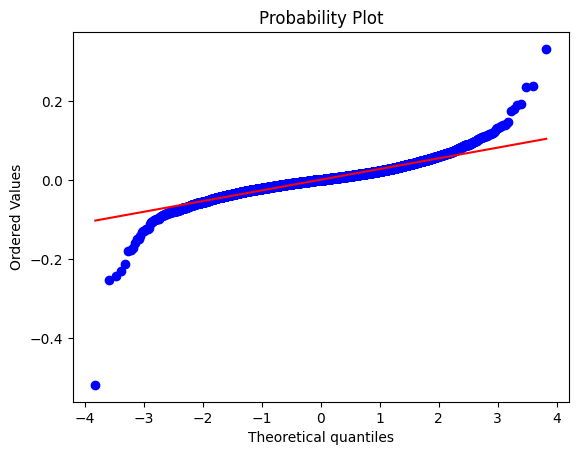

statistic: 2721.387, p-value: 0.00000
probably non gaussian
skewness: -0.3765741917618109
kurtosis: 18.13566178401052


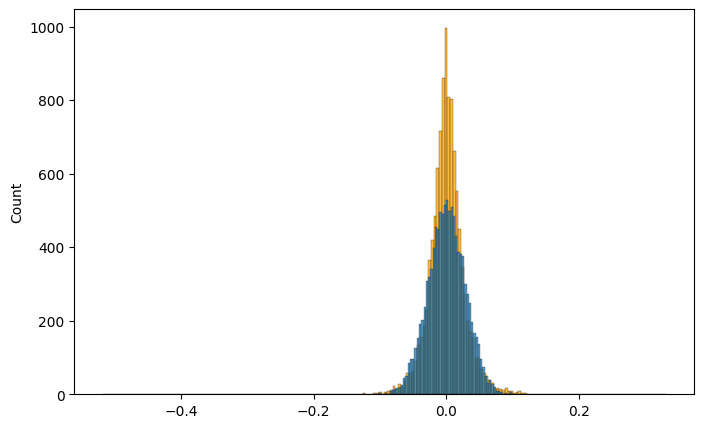

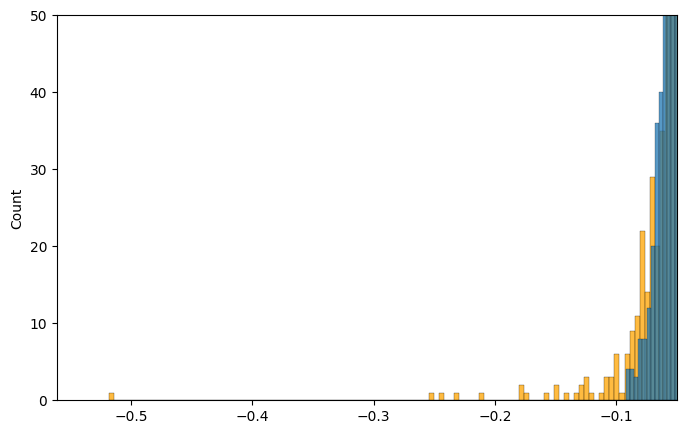

In [243]:
# now, checking for normality assumption of returns
# add returns column
df['return'] = np.nan
df.loc[1:,'return'] = (df['Adj Close'].iloc[1:].values / df['Adj Close'].iloc[:-1].values) - 1
# debug: # print(df['return'].head(5))

# check for normal distribution assumption on the returns:
returns = df.loc[1:,'return'].values
import pylab
stats.probplot(returns, dist='norm', plot=pylab)
pylab.show()


# Create a single axis
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(returns, color='orange', ax=ax)
sns.histplot(np.random.normal(loc=np.mean(returns), scale=np.std(returns), size=len(returns)), ax=ax)

# repeat with xlim, to see the tails better:
fig2, ax2 = plt.subplots(figsize=(8, 5))

sns.histplot(returns, color='orange', ax=ax2)
sns.histplot(np.random.normal(loc=np.mean(returns), scale=np.std(returns), size=len(returns)), ax=ax2)
ax2.set_xlim(right=-0.05)
ax2.set_ylim(top=50)


stat,p_val = stats.normaltest(returns)

print(f"statistic: {stat:.3f}, p-value: {p_val:.5f}")
if p_val > 0.05:
  print('probably gaussian')
else:
  print('probably non gaussian')

print(f"skewness: {stats.skew(returns)}")
print(f"kurtosis: {stats.kurtosis(returns)}")


Since Kurtosis is 18 it's a much heavier tailed distribution than a normal distribution. This can also be seen in the QQ plot (probplot)

In [224]:
df.tail()

,Date,Open,High,Low,Close,Adj Close,Volume,year,return
10603,2023-01-23,138.119995,143.320007,137.899994,141.110001,141.110001,81760300,2023,0.023500
10604,2023-01-24,140.309998,143.160004,140.300003,142.529999,142.529999,66435100,2023,0.010063
10605,2023-01-25,140.889999,142.429993,138.809998,141.860001,141.860001,65799300,2023,-0.004701
10606,2023-01-26,143.169998,144.250000,141.899994,143.960007,143.960007,54105100,2023,0.014803
10607,2023-01-27,143.160004,147.229996,143.080002,145.929993,145.929993,70492800,2023,0.013684



**Advanced Statistical Techniques (Bonus)**
Statistical Functions in NumPy: Employ NumPy’s statistical functions for in-depth stock data analysis.
E.g., Use convolve for moving averages, or np.corrcoef to explore correlations between financial metrics.
Analyze correlations between moving averages of closing prices and trading volume across time periods.

In [244]:
# Using convolve for moving averages:
adj_close_sma = df['Adj Close'].rolling(window=30).mean()
np.convolve(adj_close_sma, np.ones(30)/30)


array([        nan,         nan,         nan, ..., 13.4073333 ,
        8.93799997,  4.46925554], shape=(10637,))

In [246]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10608 entries, 0 to 10607
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       10608 non-null  datetime64[ns]
 1   Open       10608 non-null  float64       
 2   High       10608 non-null  float64       
 3   Low        10608 non-null  float64       
 4   Close      10608 non-null  float64       
 5   Adj Close  10608 non-null  float64       
 6   Volume     10608 non-null  int64         
 7   year       10608 non-null  int32         
 8   return     10607 non-null  float64       
dtypes: datetime64[ns](1), float64(6), int32(1), int64(1)
memory usage: 704.6 KB


Correlation between 1-day MA and Volume: -0.217395840673715
Correlation between 2-day MA and Volume: -0.21735820189281338
Correlation between 3-day MA and Volume: -0.2173073718975104
Correlation between 4-day MA and Volume: -0.21725974084621763
Correlation between 5-day MA and Volume: -0.2172251941163939
Correlation between 6-day MA and Volume: -0.21720103071473734
Correlation between 7-day MA and Volume: -0.21718783848367637
Correlation between 8-day MA and Volume: -0.21717496443265252
Correlation between 9-day MA and Volume: -0.21716126244044628
Correlation between 10-day MA and Volume: -0.2171529255880407
Correlation between 11-day MA and Volume: -0.21714737778359866
Correlation between 12-day MA and Volume: -0.21714335852409689
Correlation between 13-day MA and Volume: -0.21713342854280981
Correlation between 14-day MA and Volume: -0.21712691383503663
Correlation between 15-day MA and Volume: -0.21712344705004283
Correlation between 16-day MA and Volume: -0.21711798621149925
Correl

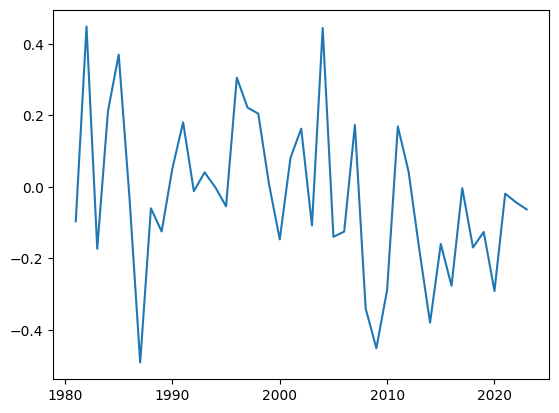


Correlation between daily returns and Volume: -0.06343516147085282


In [300]:
# correlation between moving average and the volume - slightly negative
for n in range(1,31):
  adj_close_sma = df['Adj Close'].rolling(window=n).mean().dropna()
  corr = np.corrcoef([adj_close_sma,df.loc[adj_close_sma.index,'Volume'].values])
  print(f"Correlation between {n}-day MA and Volume: {corr[0,1]}")

# regardless of window length, seems the same.
# Now check across years
n=5
corr_arr = np.array([])
for year in years_list:
  adj_close_sma = df[df['year'] == year]['Adj Close'].rolling(window=n).mean().dropna()
  corr = np.corrcoef([adj_close_sma,df.loc[adj_close_sma.index,'Volume'].values])
  print(f"Correlation between {n}-day MA and Volume in year {year}: {corr[0,1]}")
  if year == years_list[0]: corr_arr = np.array([corr[0,1]])
  else: corr_arr = np.append(corr_arr,[corr[0,1]])

# check distribution of the correlation across years
print(corr_arr)
avg_corr = np.mean(corr_arr)
print(f"\nAverage correlation across years: {avg_corr}")
std_corr = np.std(corr_arr)
print(f"Standard deviation of correlation across years: {std_corr}")
plt.plot(years_list, corr_arr)
plt.show()

# correlation between returns and the volume
corr2 = np.corrcoef([df['return'].values,df['Volume'].values])
print(f"\nCorrelation between daily returns and Volume: {corr[0,1]}")

[[ 1.00000000e+00  9.99938942e-01  9.99923130e-01  9.99838325e-01
   9.99550772e-01 -2.14807021e-01  6.55832005e-01 -1.06023853e-03]
 [ 9.99938942e-01  1.00000000e+00  9.99911215e-01  9.99923664e-01
   9.99663159e-01 -2.14284083e-01  6.55403384e-01  5.97674967e-04]
 [ 9.99923130e-01  9.99911215e-01  1.00000000e+00  9.99926626e-01
   9.99619504e-01 -2.15657831e-01  6.56229622e-01  9.66985251e-04]
 [ 9.99838325e-01  9.99923664e-01  9.99926626e-01  1.00000000e+00
   9.99717716e-01 -2.14983746e-01  6.55792730e-01  3.07362040e-03]
 [ 9.99550772e-01  9.99663159e-01  9.99619504e-01  9.99717716e-01
   1.00000000e+00 -2.17444969e-01  6.43088633e-01  2.92670292e-03]
 [-2.14807021e-01 -2.14284083e-01 -2.15657831e-01 -2.14983746e-01
  -2.17444969e-01  1.00000000e+00  1.43915088e-01  1.16597052e-03]
 [ 6.55832005e-01  6.55403384e-01  6.56229622e-01  6.55792730e-01
   6.43088633e-01  1.43915088e-01  1.00000000e+00  8.13798081e-03]
 [-1.06023853e-03  5.97674967e-04  9.66985251e-04  3.07362040e-03
   

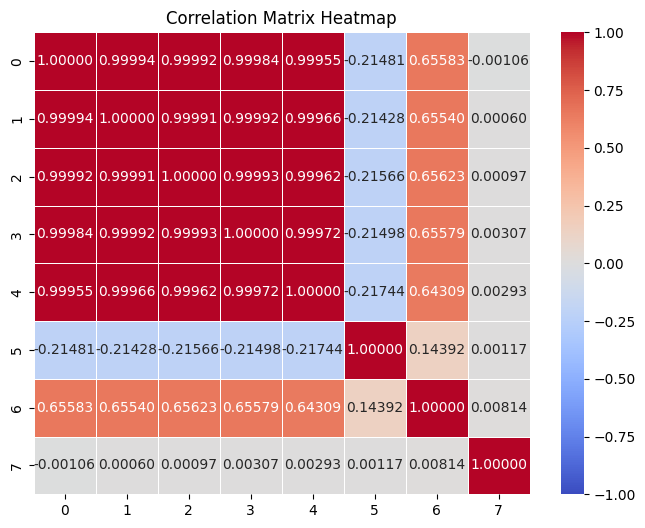

In [278]:
# Correlation matrix between all numeric non-dates variable
# via pandas: # corr_matrix = df.corr(numeric_only=True)

# via numpy:
corr_matrix = np.corrcoef(df.iloc[:,1:].dropna(), rowvar=False)

print(corr_matrix)

plt.figure(figsize=(8, 6))

# Generate heatmap with values, custom range boundaries, and color mapping
sns.heatmap(
    corr_matrix,
    annot=True,          # Display the actual numbers inside the squares
    cmap='coolwarm',     # Red for positive, blue for negative correlation
    vmin=-1, vmax=1,     # Force the scale boundaries to fit correlation limits
    fmt=".5f",           # Limit to 2 decimal places
    linewidths=0.5       # Add small gaps between squares for legibility
)

plt.title("Correlation Matrix Heatmap")
plt.show()